✅ Đã load xong packages

📂 Đang đọc file: /content/cleaned_data (1).csv 
📌 Số dòng: 10000 | Số cột: 13 

📅 Khoảng thời gian: 2024-11-01 → 2025-04-29 
🔢 Số ngày có dữ liệu: 180 
📊 Trung bình đơn/ngày: 55.56 

📈 Frequency: 7 | Độ dài: 180 ngày



Warning message in adf.test(ts_data, alternative = "stationary"):
“p-value smaller than printed p-value”



===== ADF TEST - CHUỖI GỐC =====
ADF Statistic : -5.114 
p-value       : 0.01 
Kết luận      : ✅ DỪNG 



agg_record_f4461cf2439 
                     2


===== BẬC SAI PHÂN =====
🔹 d = 0 | D = 0 | m = 7 

✅ Đã lưu adf_results.txt

Train: 166 ngày | Test: 14 ngày

===== NAIVE =====
                      ME     RMSE      MAE       MPE     MAPE      MASE
Training set  0.09090909 9.968131 7.800000 -1.522099 14.39252 0.9719436
Test set     -4.50000000 8.647873 6.928571 -9.714967 13.30207 0.8633565
                    ACF1 Theil's U
Training set -0.49622964        NA
Test set     -0.09724951  0.818689

===== SEASONAL NAIVE =====
                      ME     RMSE      MAE       MPE     MAPE     MASE
Training set -0.03773585 10.09577 8.025157 -1.793082 14.89696 1.000000
Test set      4.35714286 11.00325 9.214286  5.937798 16.27848 1.148175
                  ACF1 Theil's U
Training set 0.1283481        NA
Test set     0.1238050 0.9805074



agg_record_f4461cf2439 
                     2


===== BẢNG BASELINE =====
           Model      MAE      RMSE     MAPE      MASE ADF_pvalue d_needed
1          Naive 6.928571  8.647873 13.30207 0.8633565       0.01        0
2 Seasonal Naive 9.214286 11.003246 16.27848 1.1481751       0.01        0
  D_needed m
1        0 7
2        0 7

   📤 BÀN GIAO TV2, TV7, TV8
ADF p-value chuỗi gốc : 0.01 
Chuỗi gốc dừng?       : DỪNG ✅ 

▶ Bậc sai phân đề xuất: d = 0 | D = 0 | m = 7 
▶ TV2 (ARIMA)  dùng d = 0 
▶ TV7 (SARIMA) dùng (p,d,q)(P,D,Q)[ 7 ] với d = 0 , D = 0 
▶ TV8 (đánh giá) nhận file baseline_result.csv


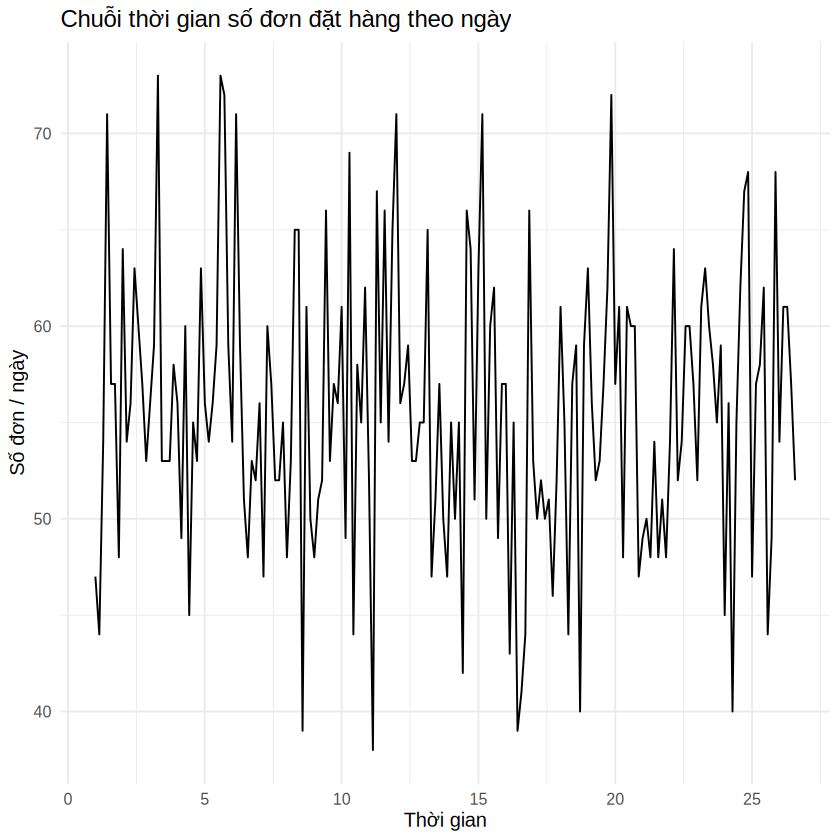

In [ ]:
# ============================================================
# TV6 - TÍNH DỪNG + BASELINE  |  R on Google Colab
# ============================================================

# ---------- 0. CÀI & LOAD PACKAGES ----------
pkgs <- c("readr","dplyr","ggplot2","forecast",
          "tseries","lubridate","tidyr","gridExtra")
for (p in pkgs) {
  if (!require(p, character.only = TRUE)) {
    install.packages(p, repos = "https://cloud.r-project.org", quiet = TRUE)
  }
  library(p, character.only = TRUE)
}
set.seed(123)
cat("✅ Đã load xong packages\n\n")

# ---------- 1. ĐỌC DỮ LIỆU ----------
paths <- c("/content/cleaned_data (1).csv")
csv_path <- paths[file.exists(paths)][1]
if (is.na(csv_path)) stop("❌ Không tìm thấy File ")
cat("📂 Đang đọc file:", csv_path, "\n")

df <- read_csv(csv_path, show_col_types = FALSE)
cat("📌 Số dòng:", nrow(df), "| Số cột:", ncol(df), "\n\n")

# ---------- 2. AGGREGATE SỐ ĐƠN THEO NGÀY ----------
date_col <- if ("order_date_clean" %in% names(df)) "order_date_clean" else "order_time"

daily_df <- df %>%
  mutate(date = as.Date(.data[[date_col]])) %>%
  group_by(date) %>%
  summarise(daily_orders = n(), .groups = "drop") %>%
  arrange(date) %>%
  complete(date = seq(min(date), max(date), by = "day"),
           fill = list(daily_orders = 0))

cat("📅 Khoảng thời gian:", format(min(daily_df$date)),
    "→", format(max(daily_df$date)), "\n")
cat("🔢 Số ngày có dữ liệu:", nrow(daily_df), "\n")
cat("📊 Trung bình đơn/ngày:", round(mean(daily_df$daily_orders), 2), "\n\n")

write_csv(daily_df, "daily_orders_tv6.csv")

# ---------- 3. TẠO TS OBJECT ----------
FREQ    <- 7
ts_data <- ts(daily_df$daily_orders, frequency = FREQ)
cat("📈 Frequency:", FREQ, "| Độ dài:", length(ts_data), "ngày\n\n")

# ---------- 4. VẼ CHUỖI GỐC ----------
p_orig <- autoplot(ts_data) +
  labs(title = "Chuỗi thời gian số đơn đặt hàng theo ngày",
       x = "Thời gian", y = "Số đơn / ngày") +
  theme_minimal(base_size = 12)
print(p_orig); ggsave("ts_original.png", p_orig, width = 10, height = 4, dpi = 150)

# ---------- 5. ADF TEST CHUỖI GỐC ----------
adf_orig <- adf.test(ts_data, alternative = "stationary")
cat("\n===== ADF TEST - CHUỖI GỐC =====\n")
cat("ADF Statistic :", round(adf_orig$statistic, 4), "\n")
cat("p-value       :", round(adf_orig$p.value, 4), "\n")
cat("Kết luận      :",
    ifelse(adf_orig$p.value < 0.05, "✅ DỪNG", "❌ KHÔNG DỪNG"), "\n\n")

# ---------- 6. ACF / PACF ----------
png("acf_pacf_original.png", width = 1400, height = 600, res = 130)
par(mfrow = c(1,2))
acf(ts_data,  lag.max = 40, main = "ACF  - Chuỗi gốc",  lwd = 2, col = "steelblue")
pacf(ts_data, lag.max = 40, main = "PACF - Chuỗi gốc", lwd = 2, col = "darkred")
par(mfrow = c(1,1)); dev.off()

# ---------- 7. XÁC ĐỊNH BẬC SAI PHÂN ----------
d_needed <- ndiffs(ts_data, test = "adf")
D_needed <- nsdiffs(ts_data, test = "seas")

cat("\n===== BẬC SAI PHÂN =====\n")
cat("🔹 d =", d_needed, "| D =", D_needed, "| m =", FREQ, "\n\n")

# ---------- 8. SAI PHÂN & KIỂM TRA LẠI ----------
# Khởi tạo biến mặc định để tránh lỗi "object not found" khi xuất file
adf_d1 <- NULL
adf_s  <- NULL

if (d_needed >= 1) {
  diff1  <- diff(ts_data, differences = 1)
  adf_d1 <- adf.test(diff1, alternative = "stationary")
  cat("ADF sau sai phân d=1: p-value =", round(adf_d1$p.value, 4),
      "→", ifelse(adf_d1$p.value < 0.05, "✅ DỪNG", "❌ CHƯA DỪNG"), "\n\n")

  png("acf_pacf_diff1.png", width = 1400, height = 600, res = 130)
  par(mfrow = c(1,2))
  acf(diff1,  lag.max = 40, main = "ACF  - Sai phân bậc 1",  col = "steelblue", lwd = 2)
  pacf(diff1, lag.max = 40, main = "PACF - Sai phân bậc 1", col = "darkred",   lwd = 2)
  par(mfrow = c(1,1)); dev.off()
}

if (D_needed >= 1) {
  diff_seasonal <- diff(ts_data, lag = FREQ, differences = 1)
  adf_s <- adf.test(diff_seasonal, alternative = "stationary")
  cat("ADF sau sai phân mùa vụ: p-value =", round(adf_s$p.value, 4),
      "→", ifelse(adf_s$p.value < 0.05, "✅ DỪNG", "❌ CHƯA DỪNG"), "\n\n")
}

# ============================================================
# ---------- 8b. XUẤT KẾT QUẢ ADF RA adf_results.txt ----------
# ============================================================
sink("adf_results.txt")

cat("==============================================\n")
cat("   KẾT QUẢ KIỂM ĐỊNH TÍNH DỪNG - TV6\n")
cat("==============================================\n\n")

cat("THÔNG TIN CHUNG\n")
cat("  Khoảng thời gian :", format(min(daily_df$date)),
    "→", format(max(daily_df$date)), "\n")
cat("  Số ngày          :", nrow(daily_df), "\n")
cat("  Frequency (m)    :", FREQ, "\n")
cat("  Mô hình          :", ifelse(FREQ == 7, "Mùa vụ tuần (7 ngày)", "Khác"), "\n\n")

cat("==============================================\n")
cat("1. ADF TEST - CHUỖI GỐC\n")
cat("==============================================\n")
cat("  ADF Statistic :", round(adf_orig$statistic, 4), "\n")
cat("  Lag order     :", adf_orig$parameter, "\n")
cat("  p-value       :", round(adf_orig$p.value, 4), "\n")
cat("  Kết luận      :",
    ifelse(adf_orig$p.value < 0.05,
           "DỪNG (bác bỏ H0)",
           "KHÔNG DỪNG (không bác bỏ H0)"), "\n\n")

cat("==============================================\n")
cat("2. XÁC ĐỊNH BẬC SAI PHÂN\n")
cat("==============================================\n")
cat("  d (sai phân thường)   :", d_needed, "\n")
cat("  D (sai phân mùa vụ)   :", D_needed, "\n")
cat("  m (frequency)         :", FREQ, "\n\n")

if (!is.null(adf_d1)) {
  cat("==============================================\n")
  cat("3. ADF TEST - SAU SAI PHÂN BẬC 1\n")
  cat("==============================================\n")
  cat("  ADF Statistic :", round(adf_d1$statistic, 4), "\n")
  cat("  Lag order     :", adf_d1$parameter, "\n")
  cat("  p-value       :", round(adf_d1$p.value, 4), "\n")
  cat("  Kết luận      :",
      ifelse(adf_d1$p.value < 0.05, "DỪNG", "CHƯA DỪNG"), "\n\n")
} else {
  cat("3. ADF TEST - SAU SAI PHÂN BẬC 1\n")
  cat("  → KHÔNG CẦN (d = 0, chuỗi gốc đã dừng)\n\n")
}

if (!is.null(adf_s)) {
  cat("==============================================\n")
  cat("4. ADF TEST - SAU SAI PHÂN MÙA VỤ\n")
  cat("==============================================\n")
  cat("  ADF Statistic :", round(adf_s$statistic, 4), "\n")
  cat("  Lag order     :", adf_s$parameter, "\n")
  cat("  p-value       :", round(adf_s$p.value, 4), "\n")
  cat("  Kết luận      :",
      ifelse(adf_s$p.value < 0.05, "DỪNG", "CHƯA DỪNG"), "\n\n")
} else {
  cat("4. ADF TEST - SAU SAI PHÂN MÙA VỤ\n")
  cat("  → KHÔNG CẦN (D = 0, không có mùa vụ rõ rệt)\n\n")
}

cat("==============================================\n")
cat("5. KẾT LUẬN VÀ BÀN GIAO\n")
cat("==============================================\n")
cat("  - Chuỗi gốc dừng? ",
    ifelse(adf_orig$p.value < 0.05, "CÓ", "KHÔNG"), "\n")
cat("  - Bậc sai phân chốt:\n")
cat("      d =", d_needed, " (sai phân thường)\n")
cat("      D =", D_needed, " (sai phân mùa vụ)\n")
cat("      m =", FREQ,     " (frequency)\n\n")
cat("  ▶ Gửi cho TV2 (ARIMA) : d =", d_needed, "\n")
cat("  ▶ Gửi cho TV7 (SARIMA): (p,d,q)(P,D,Q)[", FREQ, "] với d =",
    d_needed, ", D =", D_needed, "\n")
cat("  ▶ Gửi cho TV8 (đánh giá): baseline_result.csv\n")
cat("==============================================\n")

sink()
cat("✅ Đã lưu adf_results.txt\n\n")

# ---------- 9. CHIA TRAIN/TEST = 14 NGÀY CUỐI (theo yêu cầu TV8) ----------
H_TEST  <- 14
n       <- length(ts_data)
n_train <- n - H_TEST
train   <- window(ts_data, end   = time(ts_data)[n_train])
test    <- window(ts_data, start = time(ts_data)[n_train + 1])

cat("Train:", length(train), "ngày | Test:", length(test), "ngày\n\n")

fit_naive  <- naive(train,  h = H_TEST, level = c(80, 95))
fit_snaive <- snaive(train, h = H_TEST, level = c(80, 95))

acc_naive  <- accuracy(fit_naive,  test)
acc_snaive <- accuracy(fit_snaive, test)

cat("===== NAIVE =====\n");           print(acc_naive)
cat("\n===== SEASONAL NAIVE =====\n"); print(acc_snaive); cat("\n")

# ---------- 10. VẼ BASELINE ----------
png("baseline_forecast.png", width = 1400, height = 600, res = 130)
par(mfrow = c(1,2))
plot(fit_naive,  main = "Naive",          fcol = "steelblue", ylab = "Số đơn")
lines(test, col = "red", lwd = 2)
plot(fit_snaive, main = "Seasonal Naive", fcol = "darkgreen", ylab = "Số đơn")
lines(test, col = "red", lwd = 2)
par(mfrow = c(1,1)); dev.off()

# ---------- 11. XUẤT baseline_result.csv ----------
baseline_result <- data.frame(
  Model      = c("Naive", "Seasonal Naive"),
  MAE        = c(acc_naive["Test set","MAE"],  acc_snaive["Test set","MAE"]),
  RMSE       = c(acc_naive["Test set","RMSE"], acc_snaive["Test set","RMSE"]),
  MAPE       = c(acc_naive["Test set","MAPE"], acc_snaive["Test set","MAPE"]),
  MASE       = c(acc_naive["Test set","MASE"], acc_snaive["Test set","MASE"]),
  ADF_pvalue = c(round(adf_orig$p.value, 4), round(adf_orig$p.value, 4)),
  d_needed   = c(d_needed, d_needed),
  D_needed   = c(D_needed, D_needed),
  m          = c(FREQ, FREQ)
)
write_csv(baseline_result, "baseline_result.csv")
cat("\n===== BẢNG BASELINE =====\n"); print(baseline_result)

# ---------- 12. KẾT LUẬN BÀN GIAO ----------
cat("\n========================================\n")
cat("   📤 BÀN GIAO TV2, TV7, TV8\n")
cat("========================================\n")
cat("ADF p-value chuỗi gốc :", round(adf_orig$p.value, 4), "\n")
cat("Chuỗi gốc dừng?       :",
    ifelse(adf_orig$p.value < 0.05, "DỪNG ✅", "KHÔNG DỪNG ❌"), "\n\n")
cat("▶ Bậc sai phân đề xuất: d =", d_needed, "| D =", D_needed, "| m =", FREQ, "\n")
cat("▶ TV2 (ARIMA)  dùng d =", d_needed, "\n")
cat("▶ TV7 (SARIMA) dùng (p,d,q)(P,D,Q)[", FREQ, "] với d =",
    d_needed, ", D =", D_needed, "\n")
cat("▶ TV8 (đánh giá) nhận file baseline_result.csv\n")
cat("========================================\n")